In [85]:
import requests
import json
import matplotlib.pyplot as plt

In [86]:
# 동영상 ID
video_id = "OO2GKqyWi-M"

get url!!!
get url finished!!!!!


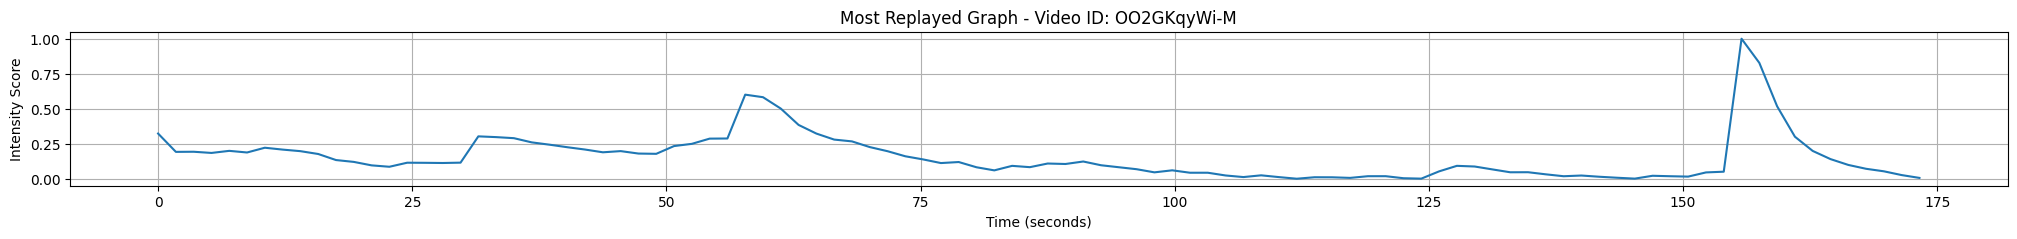

In [87]:



# API 엔드포인트 URL
url = f"https://yt.lemnoslife.com/videos?part=mostReplayed&id={video_id}"

# API 호출하여 JSON 데이터 가져오기
print('get url!!!')
response = requests.get(url)
print('get url finished!!!!!')
data = response.json()

# markers 리스트에서 startMillis와 intensityScoreNormalized 값 추출
markers = data['items'][0]['mostReplayed']['markers']
start_millis = [marker['startMillis'] for marker in markers]
intensity_scores = [marker['intensityScoreNormalized'] for marker in markers]

# 밀리초를 초로 변환
start_seconds = [millis / 1000 for millis in start_millis]

# 그래프 그리기
plt.figure(figsize=(25, 2))
plt.plot(start_seconds, intensity_scores)
plt.title(f'Most Replayed Graph - Video ID: {video_id}')
plt.xlabel('Time (seconds)')
plt.ylabel('Intensity Score')
plt.grid(True)
plt.show()


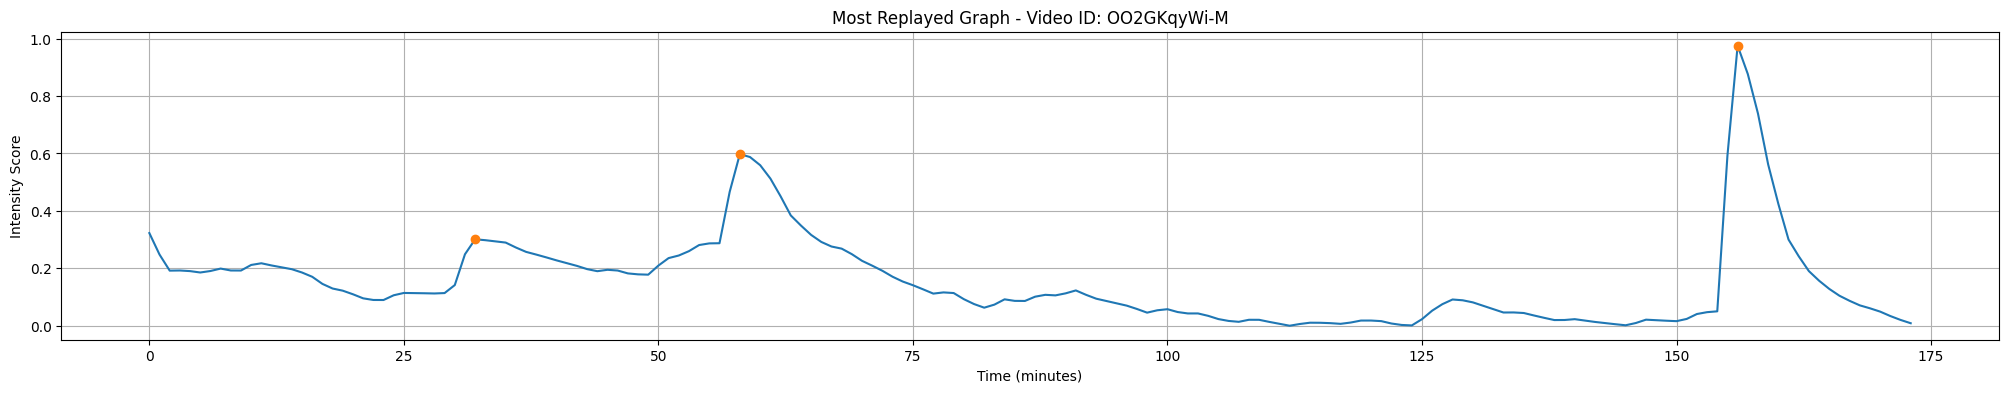

In [88]:
# 보간 함수 생성
from scipy.interpolate import interp1d
import numpy as np
from scipy.signal import find_peaks

interpolation_function = interp1d(start_seconds, intensity_scores, kind='linear', fill_value="extrapolate")

# 1초 간격으로 새로운 시간 생성
total_duration_seconds = start_seconds[-1]
new_time = np.arange(0, total_duration_seconds, 1)

# 새로운 시간에 대한 보간된 값 계산
smoothed_intensity_scores = interpolation_function(new_time)
peaks, _ = find_peaks(smoothed_intensity_scores, prominence = 0.1)

# 그래프 그리기
plt.figure(figsize=(25, 4))
plt.plot(new_time, smoothed_intensity_scores)  # 분으로 변환하여 표시
plt.plot(new_time[peaks], smoothed_intensity_scores[peaks], "o", label='Peaks')

plt.title(f'Most Replayed Graph - Video ID: {video_id}')
plt.xlabel('Time (minutes)')
plt.ylabel('Intensity Score')
plt.grid(True)
plt.show()

In [89]:
scores = smoothed_intensity_scores


In [90]:
class State:
    def __init__(self, time, count, score):
        self.time = time
        self.count = count
        self.score = score
        self.frame = 0
        self.next_states = [] # 접근할 수 있는 인덱스 저장

    def get_info(self):
        # info = f'Peak: {self.peak}, Frame: {self.frame}, Count: {self.count}, Reward: {self.reward}, Time: {self.time}, Next State {self.next_states}'
        info = f'time: {self.time}, Count: {self.count},  Next State {self.next_states}'
        print(info)




In [94]:
total_time = 10

In [95]:
max_t = total_time

In [96]:
states = [[State(time=i, count=j, score=scores[i]) for j in range(max_t + 1)] for i in range(len(scores))]


In [97]:
len(states)

174

In [98]:
min_time = 2

In [99]:
# 상태들의 next_states를 설정하는 함수
def set_next_states(states, min_time, max_t):
    n = len(states)
    for i in range(n):
        for t in range(max_t + 1):
            if i + 1 < n and t + 1 <= max_t :
                states[i][t].next_states.append((i + 1, t + 1))  # 다음 시간과 새로운 t 값
            if t >= min_time:
                for j in range(i + 2, n):
                    states[i][t].next_states.append((j, 0))  # 다음 상태의 인덱스와 새로운 t 값 0


In [100]:
set_next_states(states, min_time, max_t)

In [101]:
states[0][0].next_states

[(1, 1)]

In [102]:
import numpy as np

def select_optimal_points(states, num_points=3):
    n = len(states)
    max_t = num_points
    
    # DP 테이블과 추적 테이블 초기화
    dp = np.full((n, max_t + 1, num_points + 1), -np.inf)
    dp[:, 0, 0] = 0
    trace = np.full((n, max_t + 1, num_points + 1, 2), -1, dtype=int)  # 추적 테이블 수정

    # DP 테이블 채우기
    for i in range(n):
        for t in range(max_t + 1):
            for k in range(1, num_points + 1):
                # **수정된 부분: 유효한 상태인지 확인**
                if dp[i, t, k - 1] != -np.inf:  # 유효한 상태인 경우에만 업데이트
                    for next_i, next_t in states[i][t].next_states:
                        if next_i < n and next_t <= max_t:
                            new_score = dp[i, t, k - 1] + states[next_i][next_t].score
                            if new_score > dp[next_i, next_t, k]:
                                dp[next_i, next_t, k] = new_score
                                trace[next_i, next_t, k] = (i, t)

    # 최대 점수와 마지막 인덱스 찾기
    max_score = -np.inf
    max_index = (-1, -1, -1)
    for i in range(n):
        for t in range(max_t + 1):
            if dp[i, t, num_points] > max_score:
                max_score = dp[i, t, num_points]
                max_index = (i, t, num_points)

    # 경로 추적하여 선택된 점 찾기
    selected_points = []
    k = num_points
    while max_index != (-1, -1, -1) and k > 0:
        selected_points.append(max_index[0])
        max_index = tuple(trace[max_index[0], max_index[1], k])
        k -= 1
    
    selected_points.reverse()
    return selected_points, max_score

In [103]:
def DP(states, num_points=30):
    n = len(states)
    max_t = num_points
    
    # DP 테이블과 추적 테이블 초기화
    dp = np.full((n, max_t + 1, num_points + 1), -np.inf)
    dp[:, 0, 0] = 0
    trace = np.full((n, max_t + 1, num_points + 1, 4), -1, dtype=int)

    # DP 테이블 채우기
    for i in range(n):
        for t in range(max_t + 1):
            for k in range(1, num_points + 1):
                if dp[i, t, k - 1] != -np.inf:
                    for next_i, next_t in states[i][t].next_states:
                        # if i == 162 and t == 7 and k == num_points:
                        #     pdb.set_trace()  
                        if next_i < n and next_t <= max_t:
                            new_score = dp[i, t, k - 1] + states[next_i][next_t].score
                            if new_score > dp[next_i, next_t, k]:
                                dp[next_i, next_t, k] = new_score
                                trace[next_i, next_t, k] = (i, t, next_i, next_t)

    return dp, trace


In [104]:
def find_path(states, dp, trace, num_points=30):

    n = len(states)
    max_score = -np.inf
    max_index = (-1, -1)
    for i in range(n):
        if dp[i, 0, num_points] > max_score:
            max_score = dp[i, 0, num_points]
            max_index = (i, 0)

    # 경로 추적하여 선택된 점 찾기
    selected_points = []
    k = num_points 
    while max_index != (-1, -1) and k > 0:
        current = (max_index[0], max_index[1], trace[max_index[0], max_index[1], k][0], trace[max_index[0], max_index[1], k][1])
        selected_points.append(current)  # (next_f, next_t, prev_f, prev_t) 형식으로 저장
        max_index = tuple(trace[max_index[0], max_index[1], k][:2])
        k -= 1
    
    selected_points.reverse()

    return selected_points, max_score

In [105]:
# dp, trace = DP(states, num_points=total_time) 
# selected_tuple, max_score = find_path(states, dp, trace, num_points=total_time)


In [106]:
# selected_tuple

In [107]:
selected_points, max_score = select_optimal_points(states, num_points=total_time)


In [108]:
selected_points

[57, 58, 59, 60, 61, 155, 156, 157, 158, 159]

In [109]:
max_score

6.4687398902283055

In [110]:
def group_consecutive_points(points):
    grouped_points = []
    group = [points[0]]
    for i in range(1, len(points)):
        if points[i] == points[i-1] + 1:
            group.append(points[i])
        else:
            grouped_points.append(group)
            group = [points[i]]
    grouped_points.append(group)
    return grouped_points

In [111]:

selected_smoothed_scores = [smoothed_intensity_scores[i] for i in selected_points]

In [112]:
grouped_points = group_consecutive_points(selected_points)
group_sizes = [len(group) for group in grouped_points]

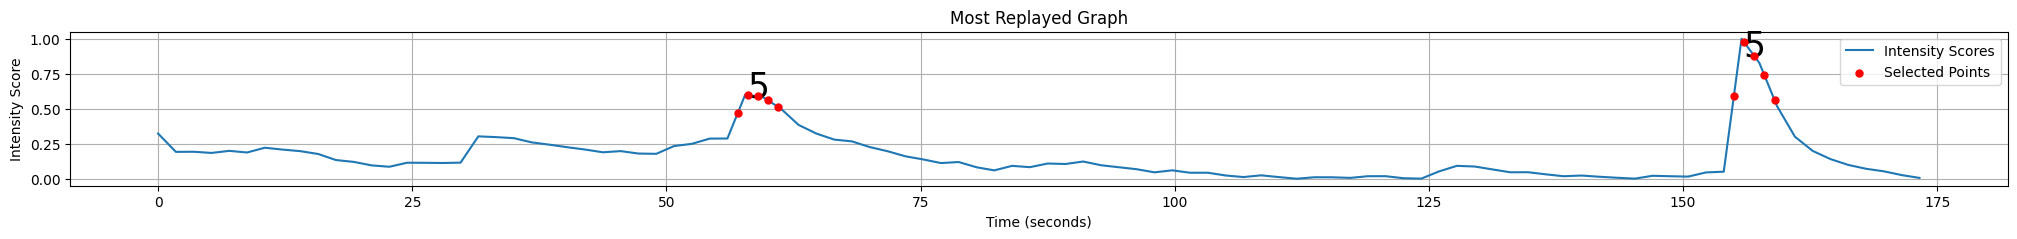

In [113]:
# 그래프 그리기
# 그래프 그리기
plt.figure(figsize=(25, 2))
plt.plot(start_seconds, intensity_scores, label='Intensity Scores')
plt.scatter(selected_points, selected_smoothed_scores, color='r', label='Selected Points', s=25, zorder=5)

# 연속된 점들의 그룹 크기를 그래프에 표시
for group, size in zip(grouped_points, group_sizes):
    mid_point = group[len(group) // 2]
    plt.text(mid_point, smoothed_intensity_scores[mid_point], str(size), color='black', fontsize=25, ha='center')

plt.title('Most Replayed Graph')
plt.xlabel('Time (seconds)')
plt.ylabel('Intensity Score')
plt.grid(True)
plt.legend()
plt.show()